# Guía práctica 4

## Ejercicio 6 - Periodograma

Datos de un electroencefalograma (EEG) contaminado por interferencia de la
frecuencia de línea.

In [18]:
from matplotlib.pyplot import show, subplots, tight_layout
from numpy import abs, arange, argmax, hanning, log10, maximum, ones, zeros
from numpy.fft import rfft, rfftfreq
from scipy.io import loadmat
from scipy.signal import welch

In [19]:
x = loadmat("eeg_practica4.mat")["x"].squeeze().astype(float)

# The samples come as uint8, so they sit around 128. The mean is removed to get
# rid of the DC term, which would otherwise dominate the spectrum.
x = x - x.mean()
n_samples = x.size

print(f"N = {n_samples} muestras")

N = 20591 muestras


### a) Determinación de la frecuencia de muestreo

La interferencia de línea es una sinusoide fuerte de 50 Hz, así que va a ser el
pico dominante del espectro.

Calculo el espectro en frecuencia normalizada $\nu$, en ciclos por muestra, que
no depende de $f_s$. Si el pico cae en $\nu_0$, entonces $50 = \nu_0 f_s$ y de
ahí sale $f_s$.

In [20]:
LINE_FREQ_HZ = 50.0

X = abs(rfft(x * hanning(n_samples)))
nu = rfftfreq(n_samples)  # Cycles per sample.

nu_line = nu[argmax(X)]
sampling_freq_hz = LINE_FREQ_HZ / nu_line

print(f"pico en nu = {nu_line:.6f} ciclos/muestra")
print(f"fs = {LINE_FREQ_HZ} / {nu_line:.6f} = {sampling_freq_hz:.2f} Hz")

pico en nu = 0.195328 ciclos/muestra
fs = 50.0 / 0.195328 = 255.98 Hz


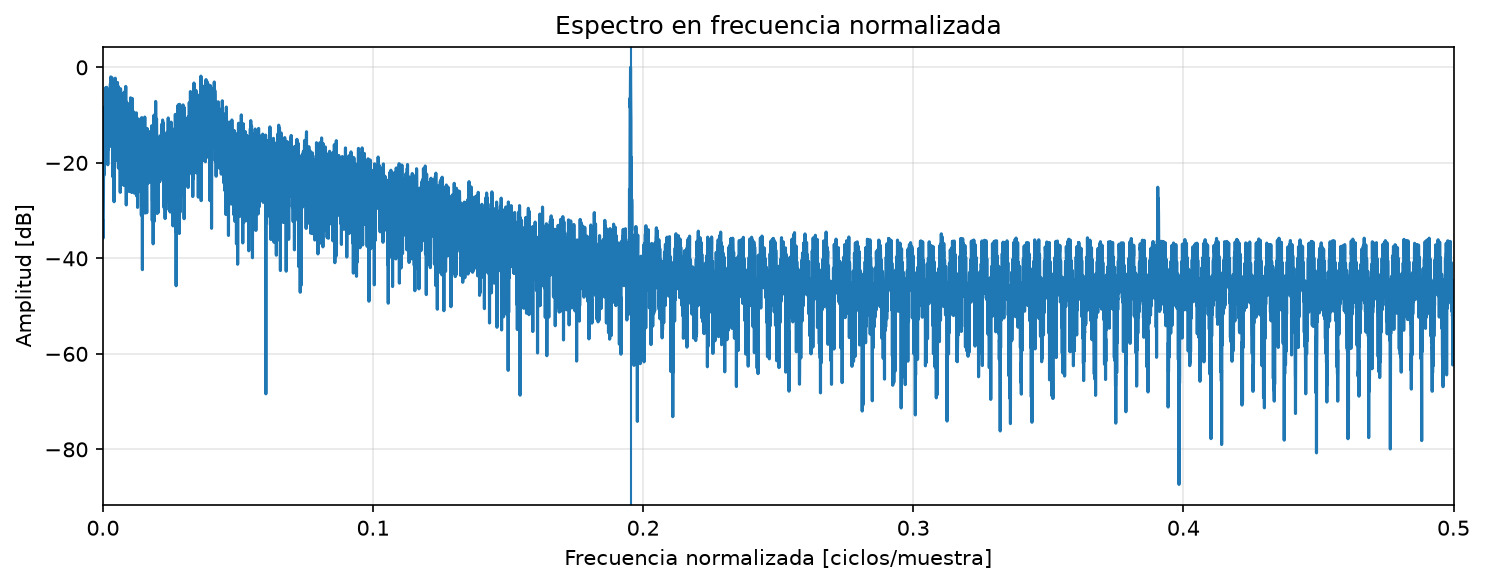

In [21]:
fig, ax = subplots(figsize=(10, 4), dpi=150)

ax.plot(nu, 20 * log10(maximum(X, 1e-12) / X.max()))
ax.axvline(nu_line, linewidth=1.0)

ax.set_title("Espectro en frecuencia normalizada")
ax.set_xlabel("Frecuencia normalizada [ciclos/muestra]")
ax.set_ylabel("Amplitud [dB]")
ax.set_xlim(0, 0.5)
ax.grid(True, alpha=0.3)
tight_layout()
show()

Da $f_s = 50/0.195328 = 255.98$ Hz, o sea 256 Hz, que es un valor típico de EEG.
La banda útil llega entonces a $f_s/2 = 128$ Hz.

Como control, con esa $f_s$ el pico queda en 50.004 Hz y aparece el segundo
armónico de la línea en 99.97 Hz.

In [22]:
sampling_freq_hz = 256.0  # Rounded to the standard EEG rate.
f_check = nu * sampling_freq_hz

for target_hz in [LINE_FREQ_HZ, 2 * LINE_FREQ_HZ]:
    near = (f_check > target_hz - 2) & (f_check < target_hz + 2)
    k = argmax(X * near)
    print(
        f"pico cerca de {target_hz:5.1f} Hz: {f_check[k]:7.3f} Hz "
        f"({20 * log10(X[k] / X.max()):5.1f} dB)"
    )

pico cerca de  50.0 Hz:  50.004 Hz (  0.0 dB)
pico cerca de 100.0 Hz:  99.971 Hz (-25.1 dB)


### b) Periodograma promediado

La resolución es $\Delta f = f_s/N$, con $N$ las muestras de cada periodograma,
así que $N = f_s/\Delta f$:

- $\Delta f = 0.1$ Hz $\rightarrow N = 2560$, alcanza para 8 segmentos.
- $\Delta f = 1$ Hz $\rightarrow N = 256$, alcanzan 80 segmentos.

El periodograma de un solo tramo es muy ruidoso y no mejora tomando más
muestras. Por eso se parte la señal en segmentos y se promedian: promediando $K$
segmentos la varianza baja en $K$.

In [23]:
def averaged_periodogram(x, n_per_segment, w, overlap=0):
    step = n_per_segment - overlap
    n_segments = 1 + (x.size - n_per_segment) // step

    psd = zeros(n_per_segment // 2 + 1)
    for i in range(n_segments):
        segment = x[i * step : i * step + n_per_segment]
        psd += abs(rfft(segment * w)) ** 2

    # Power spectral density, one-sided: everything except DC and Nyquist is
    # doubled to account for the negative frequencies that were dropped.
    psd /= n_segments * sampling_freq_hz * (w**2).sum()
    psd[1:-1] *= 2

    f = rfftfreq(n_per_segment, 1 / sampling_freq_hz)
    return f, psd, n_segments

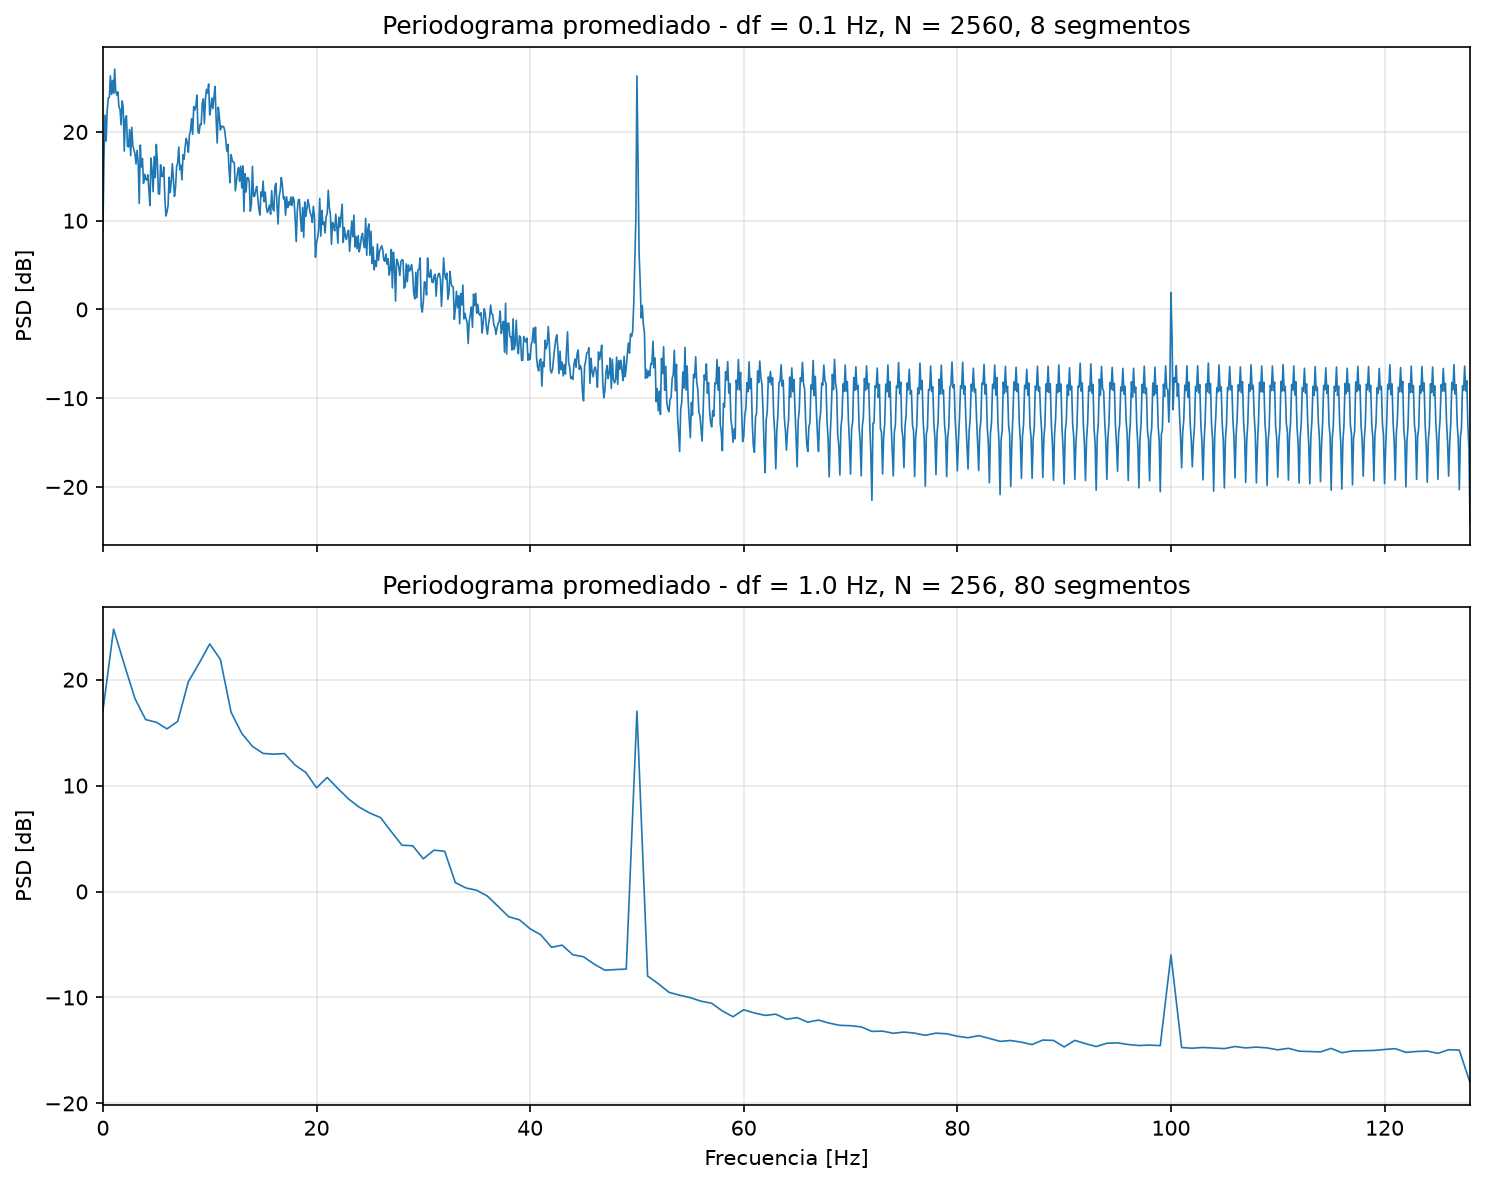

In [24]:
resolutions_hz = [0.1, 1.0]

fig, axes = subplots(len(resolutions_hz), 1, figsize=(10, 8), dpi=150, sharex=True)

for ax, freq_resolution_hz in zip(axes, resolutions_hz):
    n_per_segment = int(round(sampling_freq_hz / freq_resolution_hz))
    f, psd, n_segments = averaged_periodogram(x, n_per_segment, ones(n_per_segment))

    ax.plot(f, 10 * log10(maximum(psd, 1e-12)), "C0-", linewidth=0.8)
    ax.set_title(
        f"Periodograma promediado - df = {freq_resolution_hz} Hz, "
        f"N = {n_per_segment}, {n_segments} segmentos"
    )
    ax.set_ylabel("PSD [dB]")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Frecuencia [Hz]")
axes[-1].set_xlim(0, sampling_freq_hz / 2)
tight_layout()
show()

### c) Periodograma de Welch con ventana de Hann

Welch agrega solapamiento entre segmentos (50%) y una ventana distinta de la
rectangular.

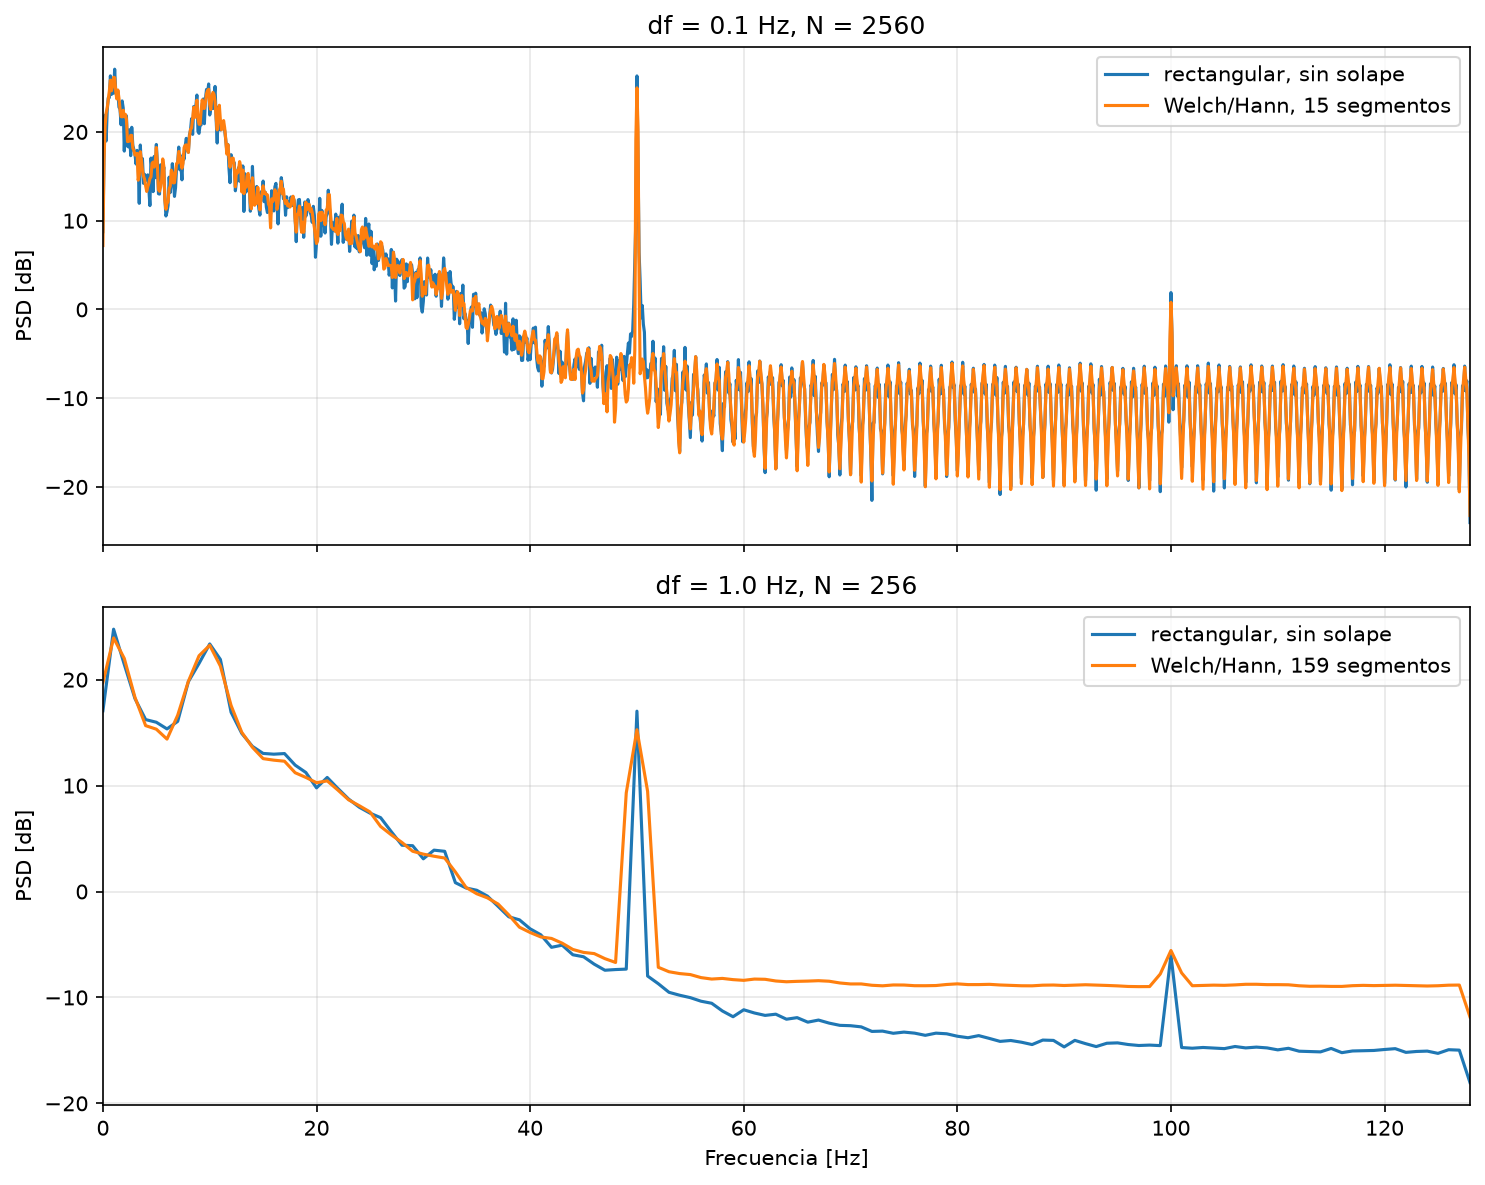

In [25]:
fig, axes = subplots(len(resolutions_hz), 1, figsize=(10, 8), dpi=150, sharex=True)

for ax, freq_resolution_hz in zip(axes, resolutions_hz):
    n_per_segment = int(round(sampling_freq_hz / freq_resolution_hz))
    w_hann = hanning(n_per_segment)

    f_rect, psd_rect, _ = averaged_periodogram(x, n_per_segment, ones(n_per_segment))
    f_hann, psd_hann, n_segments = averaged_periodogram(
        x, n_per_segment, w_hann, overlap=n_per_segment // 2
    )

    ax.plot(
        f_rect,
        10 * log10(maximum(psd_rect, 1e-12)),
        label="rectangular, sin solape",
    )
    ax.plot(
        f_hann,
        10 * log10(maximum(psd_hann, 1e-12)),
        label=f"Welch/Hann, {n_segments} segmentos",
    )

    ax.set_title(f"df = {freq_resolution_hz} Hz, N = {n_per_segment}")
    ax.set_ylabel("PSD [dB]")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Frecuencia [Hz]")
axes[-1].set_xlim(0, sampling_freq_hz / 2)
tight_layout()
show()